### Top30 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [3]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [4]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

##### Scaling

In [5]:
scaler = StandardScaler()

In [6]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [7]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [8]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [9]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [10]:
# df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [10]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [11]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [12]:
for col in ['Ticker','Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [13]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [14]:
df_train1['Ticker_encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_encoded'] = label_encoder.transform(df_test1['Ticker'])

In [15]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [16]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [17]:
features = vif_cols.copy()
features.append("Quarter")

In [18]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [19]:
ticker_encoded_train = df_train1['Ticker_encoded'].values
ticker_encoded_test = df_test1['Ticker_encoded'].values

In [20]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [21]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(8, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [22]:
num_tickers = len(label_encoder.classes_)

In [23]:

# Define bi_lstm model
bi_lstm_model = build_bi_lstm_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [24]:
X_train = X_train.reshape(-1, 11)
X_test = X_test.reshape(-1, 11)

In [25]:
np.isnan(X_test).sum()

np.int64(0)

In [26]:
df_train1['Ticker_encoded'].shape

(42985,)

In [27]:
X_train.shape

(42985, 11)

In [28]:
y_test.shape

(10788,)

In [29]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_a

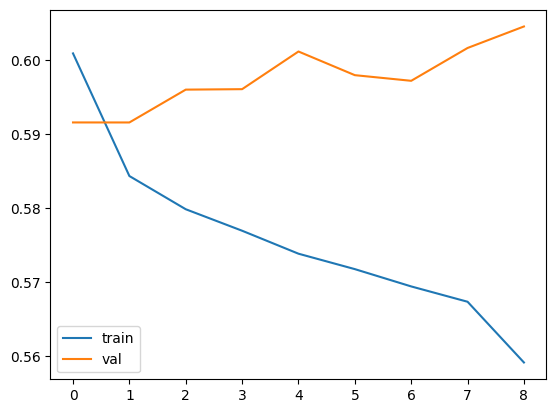

In [30]:
process_and_evaluate1(
    bi_lstm_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top30.keras',epochs=30,batch_size=16
)

In [31]:
bi_lstm_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top30.keras')

In [32]:
pred_probs_test = bi_lstm_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


In [33]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [34]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [35]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }


In [36]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [38]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.722554,0.703784,0.644310,0.224585,0.333072,"[[28081, 1644], [10282, 2978]]",Train
1,0.780868,0.629778,0.466942,0.146373,0.222880,"[[8085, 387], [1977, 339]]",Test


In [39]:
model_name = 'bi_lstm_top30'
top_n = 30

In [40]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [41]:
df_master = pd.read_excel(master_data_path)

In [42]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [43]:
# df_pred1.columns

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [47]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

# set_summary_df2 = qtr_summary_df2.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
# suffix_map = {
#     'qtr_summary_df2': '_thresh',
#     'qtr_summary_df': '_top'
# }


# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Add suffixes
# qtr_summary_df2_suff = add_suffix_to_cols(qtr_summary_df2_reset, suffix_map['qtr_summary_df2'], exclude_cols)
# qtr_summary_df_suff = add_suffix_to_cols(qtr_summary_df_reset, suffix_map['qtr_summary_df'], exclude_cols)
# ...existing code...

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4113010357.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4113010357.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4113010357.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.500578,0.464198,0.380482,0.462237,-0.019376,-0.038341,0.519954,-0.001961,...,78,289,283,262,2,8,29,166,152,116
1,2005-06-30,Train,0.344004,0.425777,0.365348,0.495418,0.045476,0.151415,0.298528,0.069641,...,92,288,285,257,4,7,35,167,150,101
2,2005-09-30,Train,0.221078,0.148182,0.113908,0.180268,0.244277,-0.040811,-0.023199,0.032085,...,64,286,277,256,3,12,33,169,158,132
3,2005-12-31,Train,0.362773,0.327526,0.410935,0.407782,0.058583,0.045009,0.304190,0.080256,...,69,284,281,275,6,9,15,171,154,126
4,2006-03-31,Train,0.032435,-0.072686,-0.085208,0.018142,0.187746,-0.014293,-0.155311,0.090828,...,64,294,285,274,1,10,21,166,155,131


In [48]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [49]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [50]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.83693916, 0.79922724, 0.77195483, ..., 0.01785337, 0.00732214,
       0.00302252], dtype=float32)

In [51]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,339,8085,387,1977,188,8300,172,2128,287,8159,313,2029
Train,2978,28081,1644,10282,1489,29174,551,11771,2303,28628,1097,10957


In [52]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [53]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7868, precision=0.5222, recall=0.0812, f1=0.1405
Train: accuracy=0.7133, precision=0.7299, recall=0.1123, f1=0.1946

Metrics for _Top50:
Test: accuracy=0.7829, precision=0.4783, recall=0.1239, f1=0.1968
Train: accuracy=0.7196, precision=0.6774, recall=0.1737, f1=0.2765

Metrics for _Thresh:
Test: accuracy=0.7809, precision=0.4669, recall=0.1464, f1=0.2229
Train: accuracy=0.7226, precision=0.6443, recall=0.2246, f1=0.3331


In [54]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [55]:
qtr_summary_df[qtr_summary_df['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
66,2021-09-30,Train,0.284202,0.218689,19,616,11,176,32,609,18,163,0.362195,0.126554,0.077993,0.157649,0.143506,0.092135


In [56]:
qtr_summary_df2[qtr_summary_df2['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Thresh,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Thresh,delta_returns_pred_vs_index_Thresh
66,2021-09-30,Train,0.202752,61,589,38,134,0.362195,0.126554,0.159444,0.076198


In [57]:
df_pred.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank',
       'Pred_Prob_bi_lstm_top30', 'Set', 'Top_30_Pred_Prob_bi_lstm_top30',
       'Top_50_Pred_Prob_bi_lstm_top30', 'Pred_Category_Top30',
       'Pred_Category_Top50'],
      dtype='object')

In [58]:
df_pred1.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank',
       'Pred_Prob_bi_lstm_top30', 'Set', 'Pred_Prob_Threshold_bi_lstm_top30',
       'Pred_Category'],
      dtype='object')

In [59]:
merged_qtr_summary[merged_qtr_summary['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
66,2021-09-30,Train,0.284202,0.218689,0.202752,0.362195,0.126554,0.077993,0.157649,0.143506,...,61,616,609,589,11,18,38,176,163,134


In [60]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [61]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.83693916, 0.79922724, 0.77195483, ..., 0.01785337, 0.00732214,
       0.00302252], dtype=float32)

In [62]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.291382
std          0.136465
min          0.000140
25%          0.197806
50%          0.276472
75%          0.364096
max          0.996614
Name: Pred_Prob_bi_lstm_top30, dtype: float64

In [63]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [64]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,339,8085,387,1977,188,8300,172,2128,287,8159,313,2029
Train,2978,28081,1644,10282,1489,29174,551,11771,2303,28628,1097,10957


In [65]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [66]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [67]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.500578,0.464198,0.380482,0.462237,-0.019376,-0.038341,0.519954,-0.001961,...,78,289,283,262,2,8,29,166,152,116
1,2005-06-30,Train,0.344004,0.425777,0.365348,0.495418,0.045476,0.151415,0.298528,0.069641,...,92,288,285,257,4,7,35,167,150,101
2,2005-09-30,Train,0.221078,0.148182,0.113908,0.180268,0.244277,-0.040811,-0.023199,0.032085,...,64,286,277,256,3,12,33,169,158,132
3,2005-12-31,Train,0.362773,0.327526,0.410935,0.407782,0.058583,0.045009,0.304190,0.080256,...,69,284,281,275,6,9,15,171,154,126
4,2006-03-31,Train,0.032435,-0.072686,-0.085208,0.018142,0.187746,-0.014293,-0.155311,0.090828,...,64,294,285,274,1,10,21,166,155,131


In [68]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top30,Set,Top_30_Pred_Prob_bi_lstm_top30,Top_50_Pred_Prob_bi_lstm_top30,Pred_Category_Top30,Pred_Category_Top50
0,diacabs,2024-12-31,0,-0.418070,777.0,0.836939,Test,True,True,FP,FP
1,sbglp,2024-12-31,0,-0.732508,803.0,0.799227,Test,True,True,FP,FP
2,wpl,2024-12-31,0,0.005329,111.0,0.771955,Test,True,True,FP,FP
3,shep,2024-12-31,1,0.269346,14.0,0.748622,Test,True,True,TP,TP
4,grv,2024-12-31,1,-0.225862,513.0,0.729402,Test,True,True,TP,TP


In [69]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.500578,0.464198,28,289,2,166,42,283,8,152,0.462237,-0.019376,-0.038341,0.519954,-0.001961,0.483574
1,2005-06-30,Train,0.344004,0.425777,26,288,4,167,43,285,7,150,0.495418,0.045476,0.151415,0.298528,0.069641,0.380301
2,2005-09-30,Train,0.221078,0.148182,27,286,3,169,38,277,12,158,0.180268,0.244277,-0.040811,-0.023199,0.032085,-0.096095
3,2005-12-31,Train,0.362773,0.327526,24,284,6,171,41,281,9,154,0.407782,0.058583,0.045009,0.304190,0.080256,0.268943
4,2006-03-31,Train,0.032435,-0.072686,29,294,1,166,40,285,10,155,0.018142,0.187746,-0.014293,-0.155311,0.090828,-0.260432


In [70]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [ ]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top30 Xform

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [73]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [76]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"
# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [77]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [78]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [79]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [80]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [81]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [82]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [83]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [84]:
from scipy.stats import skew

In [85]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [86]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [87]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [88]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [89]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


#### Power xforms

In [216]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
    # 'Target': 'none',  # Target is not a feature
}

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [217]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [218]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [219]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [220]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [221]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [222]:
features = vif_cols.copy()
features.append("Quarter")

In [223]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [225]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [99]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_xform_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(8, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [226]:
num_tickers = len(label_encoder.classes_)

In [227]:

# Define bi_lstm model
bi_lstm_xform_model = build_bi_lstm_xform_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [228]:
X_train = X_train.reshape(-1, 11)
X_test = X_test.reshape(-1, 11)

In [229]:
checkpoints_path

'D:\\Python\\Final Quant Fund\\Quant Fund\\Fund1\\src\\3yrs_as_test_data_ts'

In [31]:
# checkpoints_path = r"D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top30_xform.keras

Epoch 3: saving model to D:\Pyt

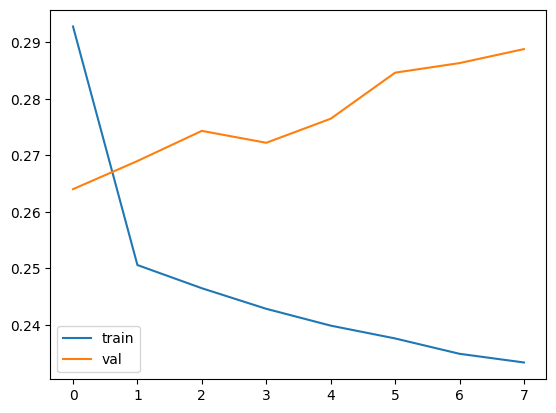

In [230]:
process_and_evaluate1(
    bi_lstm_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top30_xform.keras',epochs=30,batch_size=16
)

In [231]:
bi_lstm_x_from_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top30_xform.keras')

In [232]:
pred_probs_test = bi_lstm_x_from_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_x_from_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [233]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [234]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [235]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [236]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [237]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925509,0.762162,0.7,0.006534,0.012947,"[[39762, 9], [3193, 21]]",Train
1,0.946144,0.569581,0.1,0.001745,0.003431,"[[10206, 9], [572, 1]]",Test


In [238]:
model_name = 'bi_lstm_top30_xform'
top_n = 30

In [239]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [240]:
df_master = pd.read_excel(master_data_path)

In [241]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [242]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]

# merged_qtr_summary.reset_index(inplace=True)
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1

for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")

if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")


There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_10484\83219643.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\83219643.py:55: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\83219643.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a


Metrics for _Top30:
Test: accuracy=0.9209, precision=0.1111, recall=0.0698, f1=0.0857
Train: accuracy=0.9079, precision=0.3172, recall=0.2013, f1=0.2463

Metrics for _Top50:
Test: accuracy=0.9005, precision=0.0833, recall=0.0873, f1=0.0853
Train: accuracy=0.8897, precision=0.2753, recall=0.2912, f1=0.2830

Metrics for _Thresh:
Test: accuracy=0.9461, precision=0.1000, recall=0.0017, f1=0.0034
Train: accuracy=0.9255, precision=0.7000, recall=0.0065, f1=0.0129
All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [243]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_10484\2271013527.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\2271013527.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.722709,0.790843,0.0,1.165694,-0.019376,0.442985,0.742084,0.374851,...,0,424,412,438,14,26,0,31,23,47
1,2005-06-30,Train,0.627931,0.608667,0.0,1.375535,0.045476,0.747604,0.582455,0.766868,...,0,418,407,439,21,32,0,37,28,46
2,2005-09-30,Train,0.046874,0.063362,0.0,0.426376,0.244277,0.379502,-0.197403,0.363014,...,0,413,399,436,23,37,0,42,36,49
3,2005-12-31,Train,0.211777,0.207159,0.0,0.932621,0.058583,0.720844,0.153194,0.725462,...,0,413,399,437,24,38,0,42,36,48
4,2006-03-31,Train,0.323496,0.184084,0.0,0.503488,0.187746,0.179993,0.135750,0.319405,...,0,428,415,441,13,26,0,32,25,49


In [244]:
(merged_qtr_summary[merged_qtr_summary['Set']=='Train']['Avg_Returns_Predicted_Thresh']==0).sum()


np.int64(11)

In [245]:
df_pred.tail()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top30_xform,Set,Top_30_Pred_Prob_bi_lstm_top30_xform,Top_50_Pred_Prob_bi_lstm_top30_xform,Pred_Category_Top30,Pred_Category_Top50
53768,icicibc,2005-03-31,0,0.083870,275.0,0.000210,Train,False,False,TN,TN
53769,huin,2005-03-31,0,0.106153,255.0,0.000209,Train,False,False,TN,TN
53770,kvb,2005-03-31,0,0.048050,314.0,0.000202,Train,False,False,TN,TN
53771,ofss,2005-03-31,0,0.339122,107.0,0.000162,Train,False,False,TN,TN
53772,ttch,2005-03-31,0,0.089767,270.0,0.000145,Train,False,False,TN,TN


In [246]:
df_pred['Set'].unique()

array(['Test', 'Train'], dtype=object)

In [247]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.722709,0.790843,16,424,14,31,24,412,26,23,1.165694,-0.019376,0.442985,0.742084,0.374851,0.810219
1,2005-06-30,Train,0.627931,0.608667,9,418,21,37,18,407,32,28,1.375535,0.045476,0.747604,0.582455,0.766868,0.563191
2,2005-09-30,Train,0.046874,0.063362,7,413,23,42,13,399,37,36,0.426376,0.244277,0.379502,-0.197403,0.363014,-0.180915
3,2005-12-31,Train,0.211777,0.207159,6,413,24,42,12,399,38,36,0.932621,0.058583,0.720844,0.153194,0.725462,0.148576
4,2006-03-31,Train,0.323496,0.184084,17,428,13,32,24,415,26,25,0.503488,0.187746,0.179993,0.135750,0.319405,-0.003662


In [248]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [249]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,1,10206,9,572,40,9895,320,533,50,9665,550,523
Train,21,39762,9,3193,647,38378,1393,2567,936,37307,2464,2278


In [ ]:
D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 50 as Tgt

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [135]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [136]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [ ]:
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"
# # train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)
# qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"
# # qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [137]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [138]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [139]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [140]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [141]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

##### Scaling

In [142]:
scaler = StandardScaler()

In [143]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [144]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [151]:
# df_train.drop()

In [145]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [146]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [147]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [148]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [149]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [150]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [151]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [152]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [160]:
# df_train1['Ticker_Encoded']

In [153]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [154]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [155]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [156]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [157]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [158]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [159]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top50_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(8, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [160]:
num_tickers = len(label_encoder.classes_)

In [161]:

# Define bi_lstm model
bi_lstm_top50_model = build_bi_lstm_top50_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top50_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [162]:
X_train.shape

(42985, 11)

In [171]:
# checkpoints_path = r"D:\FY25-26\Quant Fund\Fund1\src\date_based_split"

In [163]:
y_train.shape

(42985,)


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_a

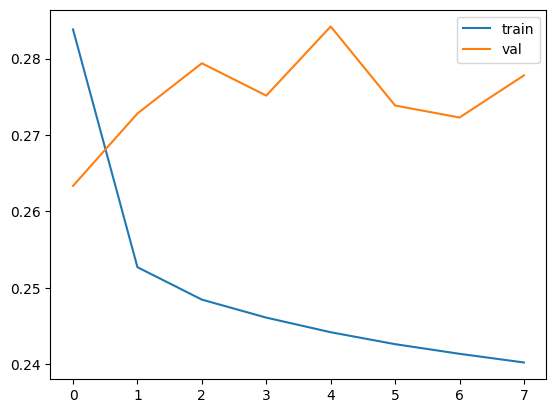

In [164]:
process_and_evaluate1(
    bi_lstm_top50_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top50.keras',epochs=40,batch_size=8
)

In [165]:
bi_lstm_top50_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top50.keras')

In [166]:
pred_probs_test = bi_lstm_top50_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top50_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [167]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [168]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [169]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [170]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [171]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925555,0.731077,0.791667,0.005912,0.011736,"[[39766, 5], [3195, 19]]",Train
1,0.945032,0.572682,0.083333,0.003490,0.006700,"[[10193, 22], [571, 2]]",Test


In [172]:
model_name = 'bi_lstm_top50'
top_n = 30

In [173]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [174]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_10484\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.715311,0.747186,0.771277,1.165694,-0.019376,0.450383,0.734687,0.418508,...,1,422,410,438,16,28,0,33,25,46
1,2005-06-30,Train,1.057692,0.756523,NaN,1.375535,0.045476,0.317843,1.012216,0.619012,...,0,422,405,439,17,34,0,33,30,46
2,2005-09-30,Train,0.097567,0.085223,0.392667,0.426376,0.244277,0.328809,-0.146710,0.341153,...,1,417,401,436,19,35,0,38,34,48
3,2005-12-31,Train,0.312150,0.329604,NaN,0.932621,0.058583,0.620471,0.253567,0.603017,...,0,415,402,437,22,35,0,40,33,48
4,2006-03-31,Train,0.200946,0.077747,0.304015,0.503488,0.187746,0.302543,0.013200,0.425741,...,1,424,410,441,17,31,0,36,30,48


In [175]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [176]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [177]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.81465596, 0.7485981 , 0.33380353, ..., 0.00134128, 0.00133572,
       0.0012219 ], dtype=float32)

In [178]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,2,10193,22,571,37,9892,323,536,50,9665,550,523
Train,19,39766,5,3195,621,38352,1419,2593,862,37233,2538,2352


In [179]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [180]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9204, precision=0.1028, recall=0.0646, f1=0.0793
Train: accuracy=0.9067, precision=0.3044, recall=0.1932, f1=0.2364

Metrics for _Top50:
Test: accuracy=0.9005, precision=0.0833, recall=0.0873, f1=0.0853
Train: accuracy=0.8862, precision=0.2535, recall=0.2682, f1=0.2607

Metrics for _Thresh:
Test: accuracy=0.9450, precision=0.0833, recall=0.0035, f1=0.0067
Train: accuracy=0.9256, precision=0.7917, recall=0.0059, f1=0.0117


In [181]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [182]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [183]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.81465596, 0.7485981 , 0.33380353, ..., 0.00134128, 0.00133572,
       0.0012219 ], dtype=float32)

In [184]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    1.078800e+04
mean     9.150752e-02
std      7.411937e-02
min      1.824857e-07
25%      3.889423e-02
50%      7.471889e-02
75%      1.257465e-01
max      8.218321e-01
Name: Pred_Prob_bi_lstm_top50, dtype: float64

In [185]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [186]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,2,10193,22,571,37,9892,323,536,50,9665,550,523
Train,19,39766,5,3195,621,38352,1419,2593,862,37233,2538,2352


In [187]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [188]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_10484\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [189]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.715311,0.747186,0.771277,1.165694,-0.019376,0.450383,0.734687,0.418508,...,1,422,410,438,16,28,0,33,25,46
1,2005-06-30,Train,1.057692,0.756523,0.771277,1.375535,0.045476,0.317843,1.012216,0.619012,...,0,422,405,439,17,34,0,33,30,46
2,2005-09-30,Train,0.097567,0.085223,0.392667,0.426376,0.244277,0.328809,-0.146710,0.341153,...,1,417,401,436,19,35,0,38,34,48
3,2005-12-31,Train,0.312150,0.329604,0.392667,0.932621,0.058583,0.620471,0.253567,0.603017,...,0,415,402,437,22,35,0,40,33,48
4,2006-03-31,Train,0.200946,0.077747,0.304015,0.503488,0.187746,0.302543,0.013200,0.425741,...,1,424,410,441,17,31,0,36,30,48


In [190]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top50,Set,Top_30_Pred_Prob_bi_lstm_top50,Top_50_Pred_Prob_bi_lstm_top50,Pred_Category_Top30,Pred_Category_Top50
0,adanigr,2024-12-31,0,-0.088450,240.0,0.814656,Test,True,True,FP,FP
1,paras,2024-12-31,0,-0.049891,176.0,0.748598,Test,True,True,FP,FP
2,sbglp,2024-12-31,0,-0.732508,803.0,0.333804,Test,True,True,FP,FP
3,cfis,2024-12-31,0,-0.096824,261.0,0.301193,Test,True,True,FP,FP
4,wesl,2024-12-31,0,-0.279325,626.0,0.300769,Test,True,True,FP,FP


In [191]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.715311,0.747186,14,422,16,33,22,410,28,25,1.165694,-0.019376,0.450383,0.734687,0.418508,0.766562
1,2005-06-30,Train,1.057692,0.756523,13,422,17,33,16,405,34,30,1.375535,0.045476,0.317843,1.012216,0.619012,0.711047
2,2005-09-30,Train,0.097567,0.085223,11,417,19,38,15,401,35,34,0.426376,0.244277,0.328809,-0.146710,0.341153,-0.159053
3,2005-12-31,Train,0.312150,0.329604,8,415,22,40,15,402,35,33,0.932621,0.058583,0.620471,0.253567,0.603017,0.271020
4,2006-03-31,Train,0.200946,0.077747,13,424,17,36,19,410,31,30,0.503488,0.187746,0.302543,0.013200,0.425741,-0.109999


In [192]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [195]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top50 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train[df_train['Target']==1]['Rank'].max()

np.float64(860.0)

In [10]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [11]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [12]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [14]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [18]:
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
    # 'Target': 'none',  # Target is not a feature
}

In [19]:
best_transform_map

{'TMR': 'yeo-johnson',
 'Momentum': 'yeo-johnson',
 'Beta': 'yeo-johnson',
 'Alpha': 'yeo-johnson',
 'EP': 'boxcox',
 'BP': 'yeo-johnson',
 'SP': 'boxcox',
 'EPS': 'yeo-johnson',
 'Zscore': 'yeo-johnson',
 'DE': 'yeo-johnson'}

In [20]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

#### Power xforms

In [21]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transform_map.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [22]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [23]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [24]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [25]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [26]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [27]:
features = vif_cols.copy()
features.append("Quarter")

In [28]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [29]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=5, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [30]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top50_xform_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(16, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [31]:
num_tickers = len(label_encoder.classes_)

In [32]:

# Define bi_lstm model
bi_lstm_top50_xform_model = build_bi_lstm_top50_xform_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top50_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [33]:
X_train.shape

(42985, 11)

In [35]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top50_xform.keras

Epoch 3: saving model to D:\Pyt

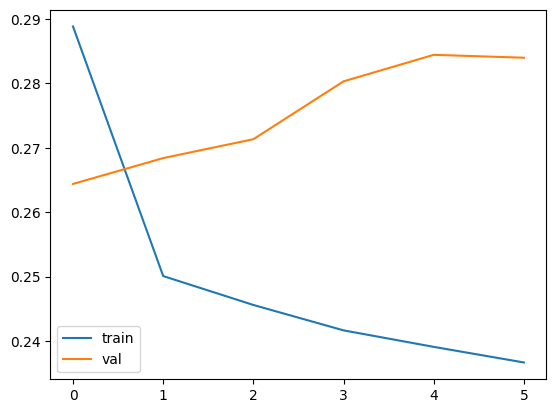

In [36]:
process_and_evaluate1(
    bi_lstm_top50_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top50_xform.keras',epochs=30,batch_size=16
)

In [37]:
bi_lstm_top50_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top50_xform.keras')

In [38]:
pred_probs_test = bi_lstm_top50_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top50_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


In [39]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [40]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [41]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [42]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [43]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925486,0.756858,0.761905,0.004978,0.009892,"[[39766, 5], [3198, 16]]",Train
1,0.946422,0.585084,0.142857,0.001745,0.003448,"[[10209, 6], [572, 1]]",Test


In [44]:
model_name = 'bi_lstm_top50_xform'
top_n = 30

In [45]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [46]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_37476\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_37476\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_37476\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.816157,0.688054,NaN,1.165694,-0.019376,0.349537,0.835532,0.477640,...,0,422,407,438,16,31,0,33,28,47
1,2005-06-30,Train,0.728025,0.655359,NaN,1.375535,0.045476,0.647511,0.682549,0.720176,...,0,420,405,439,19,34,0,35,30,46
2,2005-09-30,Train,0.092747,0.072550,NaN,0.426376,0.244277,0.333629,-0.151529,0.353826,...,0,416,401,436,20,35,0,39,34,49
3,2005-12-31,Train,0.194130,0.294343,NaN,0.932621,0.058583,0.738490,0.135547,0.638278,...,0,415,402,437,22,35,0,40,33,48
4,2006-03-31,Train,0.075311,0.262909,NaN,0.503488,0.187746,0.428177,-0.112435,0.240579,...,0,426,416,441,15,25,0,34,24,49


In [47]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [48]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([7.0395803e-01, 4.1086474e-01, 3.7592196e-01, ..., 3.4907680e-05,
       2.7389447e-05, 1.8053506e-05], dtype=float32)

In [50]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,1,10209,6,572,41,9896,319,532,68,9683,532,505
Train,16,39766,5,3198,643,38374,1397,2571,919,37290,2481,2295


In [51]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [52]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9211, precision=0.1139, recall=0.0716, f1=0.0879
Train: accuracy=0.9077, precision=0.3152, recall=0.2001, f1=0.2448

Metrics for _Top50:
Test: accuracy=0.9039, precision=0.1133, recall=0.1187, f1=0.1159
Train: accuracy=0.8889, precision=0.2703, recall=0.2859, f1=0.2779

Metrics for _Thresh:
Test: accuracy=0.9464, precision=0.1429, recall=0.0017, f1=0.0034
Train: accuracy=0.9255, precision=0.7619, recall=0.0050, f1=0.0099


In [53]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [54]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [55]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([7.0395803e-01, 4.1086474e-01, 3.7592196e-01, ..., 3.4907680e-05,
       2.7389447e-05, 1.8053506e-05], dtype=float32)

In [56]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.072501
std          0.072148
min          0.000001
25%          0.017788
50%          0.051738
75%          0.103834
max          0.747855
Name: Pred_Prob_bi_lstm_top50_xform, dtype: float64

In [57]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [58]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,1,10209,6,572,41,9896,319,532,68,9683,532,505
Train,16,39766,5,3198,643,38374,1397,2571,919,37290,2481,2295


In [59]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [60]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_37476\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_37476\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [61]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.816157,0.688054,0.0,1.165694,-0.019376,0.349537,0.835532,0.477640,...,0,422,407,438,16,31,0,33,28,47
1,2005-06-30,Train,0.728025,0.655359,0.0,1.375535,0.045476,0.647511,0.682549,0.720176,...,0,420,405,439,19,34,0,35,30,46
2,2005-09-30,Train,0.092747,0.072550,0.0,0.426376,0.244277,0.333629,-0.151529,0.353826,...,0,416,401,436,20,35,0,39,34,49
3,2005-12-31,Train,0.194130,0.294343,0.0,0.932621,0.058583,0.738490,0.135547,0.638278,...,0,415,402,437,22,35,0,40,33,48
4,2006-03-31,Train,0.075311,0.262909,0.0,0.503488,0.187746,0.428177,-0.112435,0.240579,...,0,426,416,441,15,25,0,34,24,49


In [62]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top50_xform,Set,Top_30_Pred_Prob_bi_lstm_top50_xform,Top_50_Pred_Prob_bi_lstm_top50_xform,Pred_Category_Top30,Pred_Category_Top50
0,adanigr,2024-12-31,0,-0.088450,240.0,0.703958,Test,True,True,FP,FP
1,sonacoms,2024-12-31,0,-0.224613,510.0,0.410865,Test,True,True,FP,FP
2,paras,2024-12-31,0,-0.049891,176.0,0.375922,Test,True,True,FP,FP
3,uel,2024-12-31,0,NaN,NaN,0.325332,Test,True,True,FP,FP
4,sbglp,2024-12-31,0,-0.732508,803.0,0.307455,Test,True,True,FP,FP


In [63]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.816157,0.688054,14,422,16,33,19,407,31,28,1.165694,-0.019376,0.349537,0.835532,0.477640,0.707430
1,2005-06-30,Train,0.728025,0.655359,11,420,19,35,16,405,34,30,1.375535,0.045476,0.647511,0.682549,0.720176,0.609884
2,2005-09-30,Train,0.092747,0.072550,10,416,20,39,15,401,35,34,0.426376,0.244277,0.333629,-0.151529,0.353826,-0.171727
3,2005-12-31,Train,0.194130,0.294343,8,415,22,40,15,402,35,33,0.932621,0.058583,0.738490,0.135547,0.638278,0.235759
4,2006-03-31,Train,0.075311,0.262909,15,426,15,34,25,416,25,24,0.503488,0.187746,0.428177,-0.112435,0.240579,0.075164


In [64]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [65]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 100 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [344]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [13]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [16]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [17]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [353]:
# df_train1['Ticker_Encoded']

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [23]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [26]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [27]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top100_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(16, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [28]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [29]:
num_tickers = len(label_encoder.classes_)

In [30]:

# Define bi_lstm model
bi_lstm_top100_model = build_bi_lstm_top100_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top100_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [31]:
X_train.shape

(42985, 11)

In [32]:
y_train.shape

(42985,)

In [33]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\sr

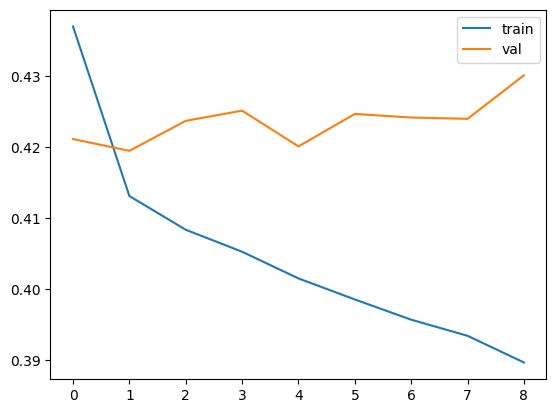

In [34]:
process_and_evaluate1(
    bi_lstm_top100_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top100.keras',epochs=30,batch_size=16
)

In [35]:
bi_lstm_top100_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top100.keras')

In [36]:
pred_probs_test = bi_lstm_top100_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top100_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [37]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [38]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [39]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [40]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [41]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.852483,0.708885,0.672932,0.027825,0.053441,"[[36465, 87], [6254, 179]]",Train
1,0.886448,0.520658,0.185567,0.015464,0.028549,"[[9545, 79], [1146, 18]]",Test


In [42]:
model_name = 'bi_lstm_top100'
top_n = 30

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_32904\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_32904\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_32904\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.765939,0.677190,0.573936,0.832432,-0.019376,0.066493,0.785315,0.155242,...,8,383,373,390,8,18,1,72,62,86
1,2005-06-30,Train,0.717590,0.598337,0.739787,0.952000,0.045476,0.234411,0.672114,0.353664,...,12,378,366,384,12,24,6,77,69,83
2,2005-09-30,Train,0.171128,0.127383,0.221192,0.331440,0.244277,0.160312,-0.073149,0.204057,...,7,375,360,385,12,27,2,80,75,91
3,2005-12-31,Train,0.474164,0.435701,0.449191,0.682739,0.058583,0.208575,0.415581,0.247039,...,7,378,369,384,10,19,4,77,66,90
4,2006-03-31,Train,0.366205,0.207922,0.184161,0.254938,0.187746,-0.111267,0.178459,0.047016,...,2,378,368,391,13,23,0,82,72,97


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([8.2869017e-01, 7.3465872e-01, 7.2460485e-01, ..., 9.4678742e-04,
       8.3904882e-04, 4.4275308e-04], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,18,9545,79,1146,53,9317,307,1111,75,9099,525,1089
Train,179,36465,87,6254,915,35427,1125,5518,1346,34498,2054,5087


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8686, precision=0.1472, recall=0.0455, f1=0.0696
Train: accuracy=0.8455, precision=0.4485, recall=0.1422, f1=0.2160

Metrics for _Top50:
Test: accuracy=0.8504, precision=0.1250, recall=0.0644, f1=0.0850
Train: accuracy=0.8339, precision=0.3959, recall=0.2092, f1=0.2738

Metrics for _Thresh:
Test: accuracy=0.8864, precision=0.1856, recall=0.0155, f1=0.0285
Train: accuracy=0.8525, precision=0.6729, recall=0.0278, f1=0.0534


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([8.2869017e-01, 7.3465872e-01, 7.2460485e-01, ..., 9.4678742e-04,
       8.3904882e-04, 4.4275308e-04], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.134062
std          0.094512
min          0.000001
25%          0.069936
50%          0.117306
75%          0.180021
max          1.000000
Name: Pred_Prob_bi_lstm_top100, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,18,9545,79,1146,53,9317,307,1111,75,9099,525,1089
Train,179,36465,87,6254,915,35427,1125,5518,1346,34498,2054,5087


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_32904\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_32904\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.765939,0.677190,0.573936,0.832432,-0.019376,0.066493,0.785315,0.155242,...,8,383,373,390,8,18,1,72,62,86
1,2005-06-30,Train,0.717590,0.598337,0.739787,0.952000,0.045476,0.234411,0.672114,0.353664,...,12,378,366,384,12,24,6,77,69,83
2,2005-09-30,Train,0.171128,0.127383,0.221192,0.331440,0.244277,0.160312,-0.073149,0.204057,...,7,375,360,385,12,27,2,80,75,91
3,2005-12-31,Train,0.474164,0.435701,0.449191,0.682739,0.058583,0.208575,0.415581,0.247039,...,7,378,369,384,10,19,4,77,66,90
4,2006-03-31,Train,0.366205,0.207922,0.184161,0.254938,0.187746,-0.111267,0.178459,0.047016,...,2,378,368,391,13,23,0,82,72,97


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top100,Set,Top_30_Pred_Prob_bi_lstm_top100,Top_50_Pred_Prob_bi_lstm_top100,Pred_Category_Top30,Pred_Category_Top50
0,easemytr,2024-12-31,0,-0.261665,589.0,0.828690,Test,True,True,FP,FP
1,metrobra,2024-12-31,0,-0.167276,387.0,0.734659,Test,True,True,FP,FP
2,atgl,2024-12-31,0,-0.208199,473.0,0.724605,Test,True,True,FP,FP
3,sbglp,2024-12-31,0,-0.732508,803.0,0.622855,Test,True,True,FP,FP
4,paras,2024-12-31,0,-0.049891,176.0,0.573603,Test,True,True,FP,FP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.765939,0.677190,22,383,8,72,32,373,18,62,0.832432,-0.019376,0.066493,0.785315,0.155242,0.696566
1,2005-06-30,Train,0.717590,0.598337,18,378,12,77,26,366,24,69,0.952000,0.045476,0.234411,0.672114,0.353664,0.552861
2,2005-09-30,Train,0.171128,0.127383,18,375,12,80,23,360,27,75,0.331440,0.244277,0.160312,-0.073149,0.204057,-0.116894
3,2005-12-31,Train,0.474164,0.435701,20,378,10,77,31,369,19,66,0.682739,0.058583,0.208575,0.415581,0.247039,0.377117
4,2006-03-31,Train,0.366205,0.207922,17,378,13,82,27,368,23,72,0.254938,0.187746,-0.111267,0.178459,0.047016,0.020176


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
model_name

'bi_lstm_top100'

In [64]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top100 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [10]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [11]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

In [12]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [13]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [14]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [16]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [17]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [18]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
}

def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [19]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [20]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [21]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [22]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [23]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [24]:
features = vif_cols.copy()
features.append("Quarter")

In [25]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [26]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [27]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top100_xform_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(16, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [28]:
num_tickers = len(label_encoder.classes_)

In [29]:

# Define bi_lstm model
bi_lstm_top100_xform_model = build_bi_lstm_top100_xform_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top100_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [30]:
X_train.shape

(42985, 11)

In [32]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top100_xform.keras

Epoch 3: saving model t

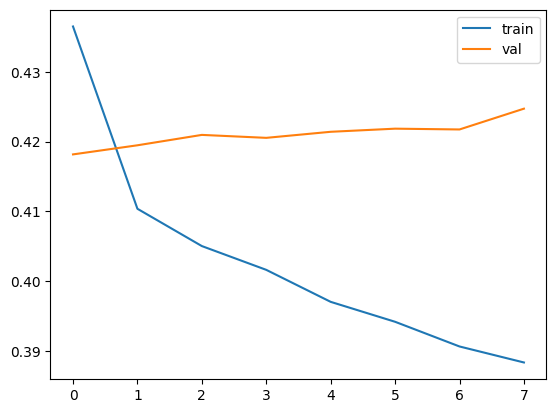

In [33]:
process_and_evaluate1(
    bi_lstm_top100_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top100_xform.keras',epochs=30,batch_size=16
)

In [34]:
bi_lstm_top100_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top100_xform.keras')

In [35]:
pred_probs_test = bi_lstm_top100_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top100_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


In [36]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [37]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [39]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [40]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [41]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.852879,0.715182,0.696751,0.030002,0.057526,"[[36468, 84], [6240, 193]]",Train
1,0.887560,0.538380,0.134328,0.007732,0.014622,"[[9566, 58], [1155, 9]]",Test


In [42]:
model_name = 'bi_lstm_top100_xform'
top_n = 30

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_12644\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_12644\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_12644\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.591557,0.630094,0.656997,0.832432,-0.019376,0.240875,0.610933,0.202339,...,8,382,371,390,9,20,1,73,64,86
1,2005-06-30,Train,1.043531,0.797370,0.523415,0.952000,0.045476,-0.091531,0.998055,0.154630,...,8,379,368,386,11,22,4,76,67,87
2,2005-09-30,Train,0.113666,0.097418,0.252567,0.331440,0.244277,0.217774,-0.130611,0.234021,...,5,370,355,384,17,32,3,85,80,93
3,2005-12-31,Train,0.428931,0.536287,0.474885,0.682739,0.058583,0.253809,0.370347,0.146452,...,4,378,368,387,10,20,1,77,67,93
4,2006-03-31,Train,0.371953,0.195763,0.517736,0.254938,0.187746,-0.117015,0.184207,0.059175,...,4,378,368,391,13,23,0,82,72,95


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([8.5286194e-01, 7.3897612e-01, 5.4559851e-01, ..., 6.3117919e-04,
       5.4079836e-04, 1.2994531e-04], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,9,9566,58,1155,35,9299,325,1129,75,9099,525,1089
Train,193,36468,84,6240,945,35457,1095,5488,1393,34545,2007,5040


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8652, precision=0.0972, recall=0.0301, f1=0.0459
Train: accuracy=0.8469, precision=0.4632, recall=0.1469, f1=0.2231

Metrics for _Top50:
Test: accuracy=0.8504, precision=0.1250, recall=0.0644, f1=0.0850
Train: accuracy=0.8361, precision=0.4097, recall=0.2165, f1=0.2833

Metrics for _Thresh:
Test: accuracy=0.8876, precision=0.1343, recall=0.0077, f1=0.0146
Train: accuracy=0.8529, precision=0.6968, recall=0.0300, f1=0.0575


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([8.5286194e-01, 7.3897612e-01, 5.4559851e-01, ..., 6.3117919e-04,
       5.4079836e-04, 1.2994531e-04], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    1.078800e+04
mean     1.271766e-01
std      9.458818e-02
min      2.640611e-07
25%      5.769290e-02
50%      1.087364e-01
75%      1.771564e-01
max      8.810881e-01
Name: Pred_Prob_bi_lstm_top100_xform, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,9,9566,58,1155,35,9299,325,1129,75,9099,525,1089
Train,193,36468,84,6240,945,35457,1095,5488,1393,34545,2007,5040


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_12644\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_12644\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.591557,0.630094,0.656997,0.832432,-0.019376,0.240875,0.610933,0.202339,...,8,382,371,390,9,20,1,73,64,86
1,2005-06-30,Train,1.043531,0.797370,0.523415,0.952000,0.045476,-0.091531,0.998055,0.154630,...,8,379,368,386,11,22,4,76,67,87
2,2005-09-30,Train,0.113666,0.097418,0.252567,0.331440,0.244277,0.217774,-0.130611,0.234021,...,5,370,355,384,17,32,3,85,80,93
3,2005-12-31,Train,0.428931,0.536287,0.474885,0.682739,0.058583,0.253809,0.370347,0.146452,...,4,378,368,387,10,20,1,77,67,93
4,2006-03-31,Train,0.371953,0.195763,0.517736,0.254938,0.187746,-0.117015,0.184207,0.059175,...,4,378,368,391,13,23,0,82,72,95


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top100_xform,Set,Top_30_Pred_Prob_bi_lstm_top100_xform,Top_50_Pred_Prob_bi_lstm_top100_xform,Pred_Category_Top30,Pred_Category_Top50
0,easemytr,2024-12-31,0,-0.261665,589.0,0.852862,Test,True,True,FP,FP
1,atgl,2024-12-31,0,-0.208199,473.0,0.738976,Test,True,True,FP,FP
2,paras,2024-12-31,0,-0.049891,176.0,0.545599,Test,True,True,FP,FP
3,metrobra,2024-12-31,0,-0.167276,387.0,0.527845,Test,True,True,FP,FP
4,sonacoms,2024-12-31,0,-0.224613,510.0,0.491930,Test,True,True,FP,FP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.591557,0.630094,21,382,9,73,30,371,20,64,0.832432,-0.019376,0.240875,0.610933,0.202339,0.649469
1,2005-06-30,Train,1.043531,0.797370,19,379,11,76,28,368,22,67,0.952000,0.045476,-0.091531,0.998055,0.154630,0.751894
2,2005-09-30,Train,0.113666,0.097418,13,370,17,85,18,355,32,80,0.331440,0.244277,0.217774,-0.130611,0.234021,-0.146859
3,2005-12-31,Train,0.428931,0.536287,20,378,10,77,30,368,20,67,0.682739,0.058583,0.253809,0.370347,0.146452,0.477704
4,2006-03-31,Train,0.371953,0.195763,17,378,13,82,27,368,23,72,0.254938,0.187746,-0.117015,0.184207,0.059175,0.008017


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 200 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [595]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [13]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [16]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [17]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [604]:
# df_train1['Ticker_Encoded']

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [23]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [26]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top200_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(16, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [27]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [28]:
num_tickers = len(label_encoder.classes_)

In [29]:

# Define bi_lstm model
bi_lstm_top200_model = build_bi_lstm_top200_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top200_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [30]:
X_train.shape

(42985, 11)

In [31]:
y_train.shape

(42985,)

In [33]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\sr

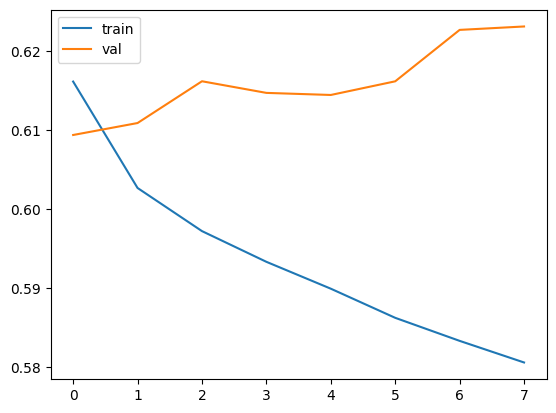

In [34]:
process_and_evaluate1(
    bi_lstm_top200_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top200.keras',epochs=30,batch_size=16
)

In [35]:
bi_lstm_top200_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top200.keras')

In [36]:
pred_probs_test = bi_lstm_top200_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top200_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [37]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [38]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [39]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [40]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [41]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.710178,0.662703,0.634100,0.077108,0.137497,"[[29534, 573], [11885, 993]]",Train
1,0.778179,0.500868,0.320856,0.025795,0.047752,"[[8335, 127], [2266, 60]]",Test


In [42]:
model_name = 'bi_lstm_top200'
top_n = 30

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_18420\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_18420\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_18420\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.632018,0.526808,0.594590,0.532415,-0.019376,-0.099603,0.651394,0.005607,...,31,290,282,289,4,12,5,165,153,160
1,2005-06-30,Train,0.593719,0.545306,0.545306,0.645971,0.045476,0.052252,0.548243,0.100665,...,38,283,279,279,8,12,12,172,156,156
2,2005-09-30,Train,0.149194,0.125506,0.109778,0.231957,0.244277,0.082763,-0.095082,0.106451,...,27,278,268,269,9,19,18,177,167,171
3,2005-12-31,Train,0.363290,0.353527,0.362089,0.471668,0.058583,0.108378,0.304707,0.118141,...,45,281,275,274,7,13,14,174,160,152
4,2006-03-31,Train,0.159190,0.199107,0.120014,0.085933,0.187746,-0.073256,-0.028556,-0.113174,...,24,282,275,280,11,18,13,178,165,173


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([6.6212499e-01, 6.4705729e-01, 6.1650705e-01, ..., 2.6113796e-03,
       1.2257847e-03, 6.2106573e-04], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,60,8335,127,2266,109,8211,251,2217,165,8027,435,2161
Train,993,29534,573,11885,1192,29259,848,11686,1908,28615,1492,10970


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7712, precision=0.3028, recall=0.0469, f1=0.0812
Train: accuracy=0.7084, precision=0.5843, recall=0.0926, f1=0.1598

Metrics for _Top50:
Test: accuracy=0.7594, precision=0.2750, recall=0.0709, f1=0.1128
Train: accuracy=0.7101, precision=0.5612, recall=0.1482, f1=0.2344

Metrics for _Thresh:
Test: accuracy=0.7782, precision=0.3209, recall=0.0258, f1=0.0478
Train: accuracy=0.7102, precision=0.6341, recall=0.0771, f1=0.1375


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([6.6212499e-01, 6.4705729e-01, 6.1650705e-01, ..., 2.6113796e-03,
       1.2257847e-03, 6.2106573e-04], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.250700
std          0.111954
min          0.000016
25%          0.175660
50%          0.250269
75%          0.324706
max          1.000000
Name: Pred_Prob_bi_lstm_top200, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,60,8335,127,2266,109,8211,251,2217,165,8027,435,2161
Train,993,29534,573,11885,1192,29259,848,11686,1908,28615,1492,10970


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_18420\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_18420\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.632018,0.526808,0.594590,0.532415,-0.019376,-0.099603,0.651394,0.005607,...,31,290,282,289,4,12,5,165,153,160
1,2005-06-30,Train,0.593719,0.545306,0.545306,0.645971,0.045476,0.052252,0.548243,0.100665,...,38,283,279,279,8,12,12,172,156,156
2,2005-09-30,Train,0.149194,0.125506,0.109778,0.231957,0.244277,0.082763,-0.095082,0.106451,...,27,278,268,269,9,19,18,177,167,171
3,2005-12-31,Train,0.363290,0.353527,0.362089,0.471668,0.058583,0.108378,0.304707,0.118141,...,45,281,275,274,7,13,14,174,160,152
4,2006-03-31,Train,0.159190,0.199107,0.120014,0.085933,0.187746,-0.073256,-0.028556,-0.113174,...,24,282,275,280,11,18,13,178,165,173


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top200,Set,Top_30_Pred_Prob_bi_lstm_top200,Top_50_Pred_Prob_bi_lstm_top200,Pred_Category_Top30,Pred_Category_Top50
0,atgl,2024-12-31,0,-0.208199,473.0,0.662125,Test,True,True,FP,FP
1,diacabs,2024-12-31,0,-0.418070,777.0,0.647057,Test,True,True,FP,FP
2,sbglp,2024-12-31,0,-0.732508,803.0,0.616507,Test,True,True,FP,FP
3,vo,2024-12-31,0,NaN,NaN,0.590355,Test,True,True,FP,FP
4,wpl,2024-12-31,1,0.005329,111.0,0.582910,Test,True,True,TP,TP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.632018,0.526808,26,290,4,165,38,282,12,153,0.532415,-0.019376,-0.099603,0.651394,0.005607,0.546184
1,2005-06-30,Train,0.593719,0.545306,22,283,8,172,38,279,12,156,0.645971,0.045476,0.052252,0.548243,0.100665,0.499830
2,2005-09-30,Train,0.149194,0.125506,21,278,9,177,31,268,19,167,0.231957,0.244277,0.082763,-0.095082,0.106451,-0.118771
3,2005-12-31,Train,0.363290,0.353527,23,281,7,174,37,275,13,160,0.471668,0.058583,0.108378,0.304707,0.118141,0.294944
4,2006-03-31,Train,0.159190,0.199107,19,282,11,178,32,275,18,165,0.085933,0.187746,-0.073256,-0.028556,-0.113174,0.011362


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top200 xform

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [3]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [4]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"


In [5]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [6]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [7]:
df_test['Quarter'].unique()

<DatetimeArray>
['2022-03-31 00:00:00', '2022-06-30 00:00:00', '2022-09-30 00:00:00',
 '2022-12-31 00:00:00', '2023-03-31 00:00:00', '2023-06-30 00:00:00',
 '2023-09-30 00:00:00', '2023-12-31 00:00:00', '2024-03-31 00:00:00',
 '2024-06-30 00:00:00', '2024-09-30 00:00:00', '2024-12-31 00:00:00']
Length: 12, dtype: datetime64[ns]

In [8]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [9]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [10]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [11]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [12]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

In [14]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [15]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [17]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [18]:
best_transforms

{'TMR': 'yeo-johnson',
 'Momentum': 'yeo-johnson',
 'Beta': 'yeo-johnson',
 'Alpha': 'yeo-johnson',
 'EP': 'boxcox',
 'BP': 'yeo-johnson',
 'SP': 'boxcox',
 'Dividend_Flag': 'original',
 'DE': 'yeo-johnson',
 'EPS': 'yeo-johnson',
 'Zscore': 'yeo-johnson'}

In [18]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [19]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [20]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }
# 1. Decide best transform for each feature based on your previous results
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson', # Added based on your result

    # The following are either not in your results or don't require transformation:
    # 'FCF': 'yeo-johnson',
    # 'ICR': 'yeo-johnson',
    # 'Year': 'log1p',
    # 'Quarter_number': 'boxcox',  
    # 'Dividend_Flag': 'original', # Excluded since the best transform is 'original' (no transform)
}
def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [25]:
import pickle 
filename = r'D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform_standard_scaler.pkl'
pickle.dump(scaler, open(filename, 'wb'))

In [26]:
check = pd.Series(y_train)
check.unique()

array([1, 0])

In [27]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [28]:
# import pickle 
# filename = r'D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform_label_encoder.pkl'
# pickle.dump(scaler, open(filename, 'wb'))
np.save(r'D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform_label_encoder.npy', label_encoder.classes_)

In [29]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [23]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [30]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [31]:
features = vif_cols.copy()
features.append("Quarter")

In [32]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [33]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### Bi-LSTM

In [34]:
from tensorflow.keras.layers import Bidirectional

def build_bi_lstm_top200_xform_model(input_shape, embedding_size, num_tickers):
    ticker_input = Input(shape=(1,), name='ticker_input')
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size, input_length=1)(ticker_input)
    ticker_embedding_flat = Flatten()(ticker_embedding)
    
    continuous_input = Input(shape=(input_shape[1],), name='continuous_input')
    merged = Concatenate()([ticker_embedding_flat, continuous_input])
    reshaped_input = tf.keras.layers.Reshape((1, -1))(merged)
    bi_lstm_layer = Bidirectional(LSTM(16, activation='relu',dropout=0.2))(reshaped_input)
    output = Dense(1, activation='sigmoid')(bi_lstm_layer)    
    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [35]:
num_tickers = len(label_encoder.classes_)

In [36]:

# Define bi_lstm model
bi_lstm_top200_xform_model = build_bi_lstm_top200_xform_model(X_train.shape, embedding_size, num_tickers)
bi_lstm_top200_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [37]:
X_train.shape

(42985, 11)

In [45]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\bi_lstm_top200_xform.keras

Epoch 3: saving model t

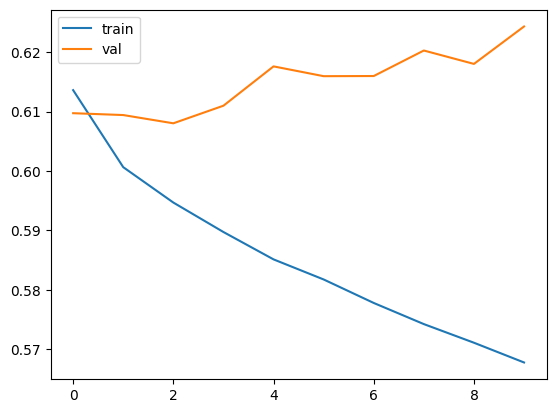

In [40]:
process_and_evaluate1(
    bi_lstm_top200_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\bi_lstm_top200_xform.keras',epochs=30,batch_size=16
)

In [44]:
checkpoints_path = r"D:\FY25-26\Quant Fund\Fund1\src\3yrs_as_test_data_ts"

In [46]:
bi_lstm_top200_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\bi_lstm_top200_xform.keras')

In [47]:
pred_probs_test = bi_lstm_top200_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top200_xform_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [48]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [49]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [50]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [51]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [52]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.718553,0.688932,0.638988,0.139230,0.228641,"[[29094, 1013], [11085, 1793]]",Train
1,0.772710,0.520844,0.291391,0.037833,0.066971,"[[8248, 214], [2238, 88]]",Test


In [53]:
model_name = 'bi_lstm_top200_xform'
top_n = 30

In [54]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [55]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_31788\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_31788\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_31788\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.726988,0.592909,0.471034,0.532415,-0.019376,-0.194573,0.746364,-0.060494,...,62,291,285,267,3,9,27,164,150,129
1,2005-06-30,Train,0.496310,0.539588,0.478733,0.645971,0.045476,0.149661,0.450834,0.106383,...,66,283,279,256,8,12,35,172,156,128
2,2005-09-30,Train,0.119572,0.176976,0.159740,0.231957,0.244277,0.112385,-0.124705,0.054981,...,62,276,273,256,11,14,31,179,162,136
3,2005-12-31,Train,0.477432,0.456696,0.375711,0.471668,0.058583,-0.005764,0.418849,0.014972,...,82,285,281,263,3,7,25,170,154,115
4,2006-03-31,Train,0.088244,0.017637,0.065923,0.085933,0.187746,-0.002311,-0.099502,0.068296,...,45,282,272,262,11,21,31,178,168,152


In [56]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [57]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [58]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.694206  , 0.64769363, 0.63812566, ..., 0.00185098, 0.00107301,
       0.0007642 ], dtype=float32)

In [59]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,88,8248,214,2238,98,8200,262,2228,163,8025,437,2163
Train,1793,29094,1013,11085,1301,29368,739,11577,2054,28761,1346,10824


In [60]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [61]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7692, precision=0.2722, recall=0.0421, f1=0.0730
Train: accuracy=0.7135, precision=0.6377, recall=0.1010, f1=0.1744

Metrics for _Top50:
Test: accuracy=0.7590, precision=0.2717, recall=0.0701, f1=0.1114
Train: accuracy=0.7169, precision=0.6041, recall=0.1595, f1=0.2524

Metrics for _Thresh:
Test: accuracy=0.7727, precision=0.2914, recall=0.0378, f1=0.0670
Train: accuracy=0.7186, precision=0.6390, recall=0.1392, f1=0.2286


In [62]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [63]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [64]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.694206  , 0.64769363, 0.63812566, ..., 0.00185098, 0.00107301,
       0.0007642 ], dtype=float32)

In [65]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.251432
std          0.118822
min          0.000001
25%          0.168759
50%          0.247678
75%          0.324078
max          0.932754
Name: Pred_Prob_bi_lstm_top200_xform, dtype: float64

In [66]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [67]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,88,8248,214,2238,98,8200,262,2228,163,8025,437,2163
Train,1793,29094,1013,11085,1301,29368,739,11577,2054,28761,1346,10824


In [68]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [69]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_31788\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_31788\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [70]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.726988,0.592909,0.471034,0.532415,-0.019376,-0.194573,0.746364,-0.060494,...,62,291,285,267,3,9,27,164,150,129
1,2005-06-30,Train,0.496310,0.539588,0.478733,0.645971,0.045476,0.149661,0.450834,0.106383,...,66,283,279,256,8,12,35,172,156,128
2,2005-09-30,Train,0.119572,0.176976,0.159740,0.231957,0.244277,0.112385,-0.124705,0.054981,...,62,276,273,256,11,14,31,179,162,136
3,2005-12-31,Train,0.477432,0.456696,0.375711,0.471668,0.058583,-0.005764,0.418849,0.014972,...,82,285,281,263,3,7,25,170,154,115
4,2006-03-31,Train,0.088244,0.017637,0.065923,0.085933,0.187746,-0.002311,-0.099502,0.068296,...,45,282,272,262,11,21,31,178,168,152


In [71]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_bi_lstm_top200_xform,Set,Top_30_Pred_Prob_bi_lstm_top200_xform,Top_50_Pred_Prob_bi_lstm_top200_xform,Pred_Category_Top30,Pred_Category_Top50
0,sbglp,2024-12-31,0,-0.732508,803.0,0.694206,Test,True,True,FP,FP
1,atgl,2024-12-31,0,-0.208199,473.0,0.647694,Test,True,True,FP,FP
2,ade,2024-12-31,0,NaN,NaN,0.638126,Test,True,True,FP,FP
3,diacabs,2024-12-31,0,-0.418070,777.0,0.622277,Test,True,True,FP,FP
4,jys,2024-12-31,0,-0.318690,704.0,0.613331,Test,True,True,FP,FP


In [72]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.726988,0.592909,27,291,3,164,41,285,9,150,0.532415,-0.019376,-0.194573,0.746364,-0.060494,0.612285
1,2005-06-30,Train,0.496310,0.539588,22,283,8,172,38,279,12,156,0.645971,0.045476,0.149661,0.450834,0.106383,0.494112
2,2005-09-30,Train,0.119572,0.176976,19,276,11,179,36,273,14,162,0.231957,0.244277,0.112385,-0.124705,0.054981,-0.067300
3,2005-12-31,Train,0.477432,0.456696,27,285,3,170,43,281,7,154,0.471668,0.058583,-0.005764,0.418849,0.014972,0.398112
4,2006-03-31,Train,0.088244,0.017637,19,282,11,178,29,272,21,168,0.085933,0.187746,-0.002311,-0.099502,0.068296,-0.170109


In [73]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [74]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_bi_LSTM_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

In [501]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)

def label_prediction(row, model_name):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_{top_n}_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

set_summary_df = qtr_summary_df.groupby('Set').agg(
    Count_TP = ('Count_TP','sum'),
    Count_TN = ('Count_TN','sum'),
    Count_FP = ('Count_FP','sum'),
    Count_FN = ('Count_FN','sum')
)

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'

df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
    print("there are quarters where there were no 1s by the model")
else:
    print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted']
qtr_summary_df['delta_returns_pred_vs_index'] = qtr_summary_df['Avg_Returns_Predicted']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted']
qtr_summary_df2['delta_returns_pred_vs_index'] = qtr_summary_df2['Avg_Returns_Predicted']-qtr_summary_df2['Index_Returns']

set_summary_df2 = qtr_summary_df2.groupby('Set').agg(
    Count_TP = ('Count_TP','sum'),
    Count_TN = ('Count_TN','sum'),
    Count_FP = ('Count_FP','sum'),
    Count_FN = ('Count_FN','sum')
)

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
suffix_map = {
    'qtr_summary_df2': '_thresh',
    'qtr_summary_df': '_top'
}

def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Add suffixes
qtr_summary_df2_suff = add_suffix_to_cols(qtr_summary_df2_reset, suffix_map['qtr_summary_df2'], exclude_cols)
qtr_summary_df_suff = add_suffix_to_cols(qtr_summary_df_reset, suffix_map['qtr_summary_df'], exclude_cols)
# ...existing code...

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_suff, qtr_summary_df2_suff,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_top',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_top','delta_returns_pred_vs_index_top',
     'Avg_Returns_Predicted_thresh',
    'delta_returns_act_vs_pred_thresh',
     'delta_returns_pred_vs_index_thresh',
    'Count_TP_top', 'Count_TP_thresh',
    'Count_TN_top', 'Count_TN_thresh',
    'Count_FP_top', 'Count_FP_thresh',
    'Count_FN_top', 'Count_FN_thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\35098\AppData\Local\Temp\ipykernel_19200\579352680.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\35098\AppData\Local\Temp\ipykernel_19200\579352680.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\35098\AppData\Local\Temp\ipykernel_19200\579352680.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

there are quarters where there were no 1s by the model


,Quarter,Set,Avg_Returns_Predicted_top,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_top,delta_returns_pred_vs_index_top,Avg_Returns_Predicted_thresh,delta_returns_act_vs_pred_thresh,delta_returns_pred_vs_index_thresh,Count_TP_top,Count_TP_thresh,Count_TN_top,Count_TN_thresh,Count_FP_top,Count_FP_thresh,Count_FN_top,Count_FN_thresh
0,2005-03-31,Train,0.494907,0.532415,-0.019376,0.037508,0.514283,0.472369,0.060046,0.491745,26,62,290,276,4,18,165,129
1,2005-06-30,Train,0.484710,0.645971,0.045476,0.161261,0.439234,0.459202,0.186769,0.413726,21,64,282,259,9,32,173,130
2,2005-09-30,Train,0.203195,0.231957,0.244277,0.028762,-0.041082,0.143415,0.088543,-0.100862,24,52,281,256,6,31,174,146
3,2005-12-31,Train,0.290253,0.471668,0.058583,0.181415,0.231670,0.320186,0.151482,0.261603,22,79,280,255,8,33,175,118
4,2006-03-31,Train,0.143523,0.085933,0.187746,-0.057590,-0.044223,-0.011768,0.097701,-0.199513,22,38,285,263,8,30,175,159


In [502]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.8059319 , 0.7803881 , 0.64804995, ..., 0.00809071, 0.00642805,
       0.00498803], dtype=float32)

In [503]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_thresh = ('Count_TP_thresh','sum'),
    Count_TN_thresh = ('Count_TN_thresh','sum'),
    Count_FP_thresh = ('Count_FP_thresh','sum'),
    Count_FN_thresh = ('Count_FN_thresh','sum'),
    Count_TP_top = ('Count_TP_top','sum'),
    Count_TN_top = ('Count_TN_top','sum'),
    Count_FP_top = ('Count_FP_top','sum'),
    Count_FN_top = ('Count_FN_top','sum')
)
set_summary_df3

,Count_TP_thresh,Count_TN_thresh,Count_FP_thresh,Count_FN_thresh,Count_TP_top,Count_TN_top,Count_FP_top,Count_FN_top
Set,,,,,,,,
Test,190,15083,452,4461,217,15032,503,4434
Train,1734,22029,1005,8819,1080,22434,600,9473


In [504]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [505]:
for suffix in ['_top', '_thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _top:
Test: accuracy=0.7554, precision=0.3014, recall=0.0467, f1=0.0808
Train: accuracy=0.7001, precision=0.6429, recall=0.1023, f1=0.1766

Metrics for _thresh:
Test: accuracy=0.7566, precision=0.2960, recall=0.0409, f1=0.0718
Train: accuracy=0.7075, precision=0.6331, recall=0.1643, f1=0.2609


In [506]:
if merged_qtr_summary['Avg_Returns_Predicted_thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_top'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
else:
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have different returns")

Both the stock picking strategies (Top 50 and Pred prob theshold) have different returns


In [507]:
qtr_summary_df[qtr_summary_df['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted,Count_TP,Count_TN,Count_FP,Count_FN,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred,delta_returns_pred_vs_index
66,2021-09-30,Test,0.131145,11,610,19,182,0.484905,0.126554,0.35376,0.004591


In [508]:
qtr_summary_df2[qtr_summary_df2['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted,Count_TP,Count_TN,Count_FP,Count_FN,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred,delta_returns_pred_vs_index
66,2021-09-30,Test,0.058136,6,615,14,187,0.484905,0.126554,0.426769,-0.068418


In [509]:
df_pred.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank',
       'Pred_Prob_bi_lstm_top200_xform', 'Set',
       'Top_30_Pred_Prob_bi_lstm_top200_xform', 'Pred_Category'],
      dtype='object')

In [510]:
merged_qtr_summary[merged_qtr_summary['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_top,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_top,delta_returns_pred_vs_index_top,Avg_Returns_Predicted_thresh,delta_returns_act_vs_pred_thresh,delta_returns_pred_vs_index_thresh,Count_TP_top,Count_TP_thresh,Count_TN_top,Count_TN_thresh,Count_FP_top,Count_FP_thresh,Count_FN_top,Count_FN_thresh
66,2021-09-30,Test,0.131145,0.484905,0.126554,0.35376,0.004591,0.058136,0.426769,-0.068418,11,6,610,615,19,14,182,187


In [511]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_top'].isna()].shape

(1, 18)

In [512]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.8059319 , 0.7803881 , 0.64804995, ..., 0.00809071, 0.00642805,
       0.00498803], dtype=float32)

In [513]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [514]:
merged_qtr_summary['Avg_Returns_Predicted_top'] = merged_qtr_summary['Avg_Returns_Predicted_top'].ffill()

In [516]:
top_n

30

In [ ]:
# with pd.ExcelWriter(r"D:\FY25-26\Quant Fund\Fund1\results\top200\Pred_Vs_Act_bi_LSTM_xform_time_split_03_07_2025.xlsx", ) as writer:
#     merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
#     qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_top200_pred', index=False)
#     qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_50_threshold', index=False)
#     df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_top200_pred', index=False)
#     df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_50_threshold', index=False)
#     set_summary_df.to_excel(writer, sheet_name='Set_Summary_top200_pred')
#     set_summary_df2.to_excel(writer, sheet_name='Set_Summary_50_threshold')